In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [8]:
df = pd.read_csv("Advertising.csv")

print("Dataset Loaded Successfully!")
display(df.head())

Dataset Loaded Successfully!


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (200, 5)

Column Names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Statistical Summary:


,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [10]:
df.columns = df.columns.str.strip()

df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df = df.drop_duplicates()
df = df.dropna()

print("Missing Values:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
display(df.head())

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Cleaned Dataset:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


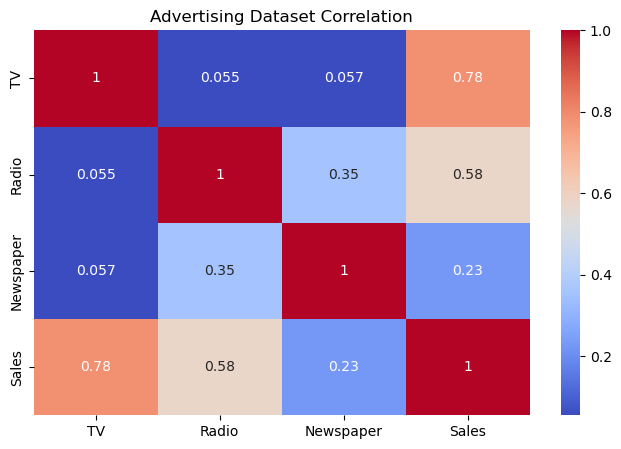

In [11]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Advertising Dataset Correlation")
plt.show()

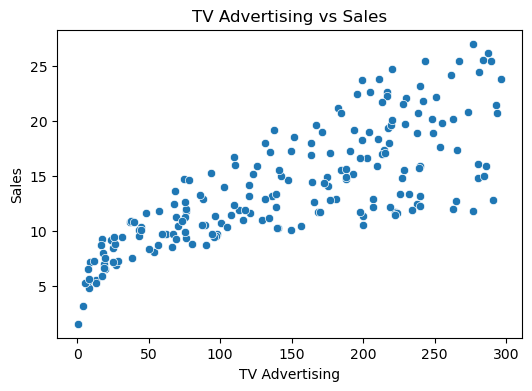

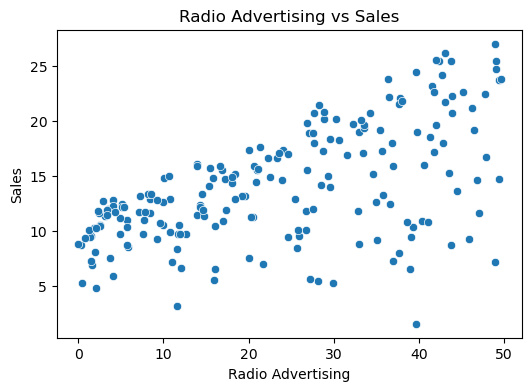

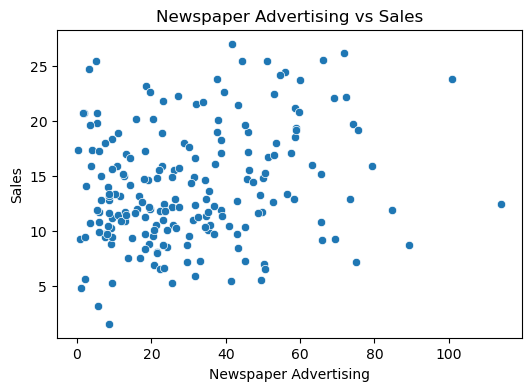

In [12]:
features = ["TV", "Radio", "Newspaper"]

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x=feature, y="Sales")
    plt.title(feature + " Advertising vs Sales")
    plt.xlabel(feature + " Advertising")
    plt.ylabel("Sales")
    plt.show()

In [13]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 3)
Testing Data: (40, 3)


In [14]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [15]:
y_pred = model.predict(X_test)

print("Actual Sales:")
print(y_test.head().values)

print("\nPredicted Sales:")
print(y_pred[:5])

Actual Sales:
[16.9 22.4 21.4  7.3 24.7]

Predicted Sales:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326]


In [16]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-----------------------")

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))
print("R2 Percentage:", round(r2 * 100, 2), "%")

MODEL PERFORMANCE
-----------------------
MAE: 1.461
MSE: 3.174
RMSE: 1.782
R2 Score: 0.899
R2 Percentage: 89.94 %


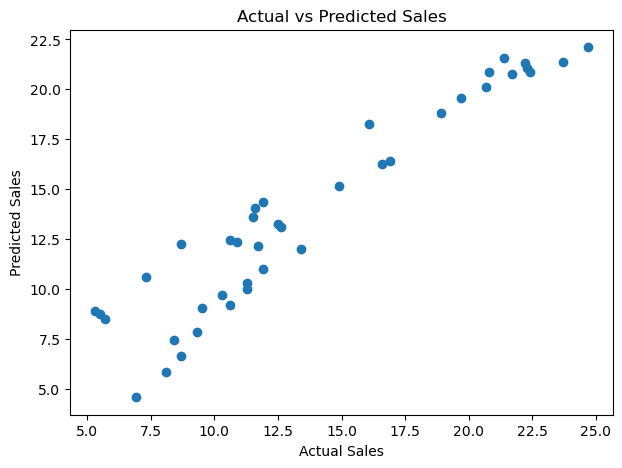

In [17]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted Sales")

plt.show()

In [18]:
new_ad = pd.DataFrame([{
    "TV": 200,
    "Radio": 40,
    "Newspaper": 30
}])

predicted_sales = model.predict(new_ad)

print("New Advertising Budget:")
display(new_ad)

print("Predicted Sales:", round(predicted_sales[0], 2))

New Advertising Budget:


,TV,Radio,Newspaper
0,200,40,30


Predicted Sales: 19.58
